In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import datasets

In [4]:
data=pd.read_csv("IRIS (1).csv")
data

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [5]:
iris=datasets.load_iris()

In [6]:
x=iris.data
y=iris.target
names=iris.target_names

In [7]:
x.shape

(150, 4)

In [8]:
y.shape

(150,)

In [9]:
df=pd.DataFrame(x,columns=iris.feature_names)
df["species"]=iris.target
df["species"]=df["species"].replace(to_replace=[0,1,2],value=["setpsa","versicolor","virginica"])
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setpsa
1,4.9,3.0,1.4,0.2,setpsa
2,4.7,3.2,1.3,0.2,setpsa
3,4.6,3.1,1.5,0.2,setpsa
4,5.0,3.6,1.4,0.2,setpsa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


## Exploratory data analysis

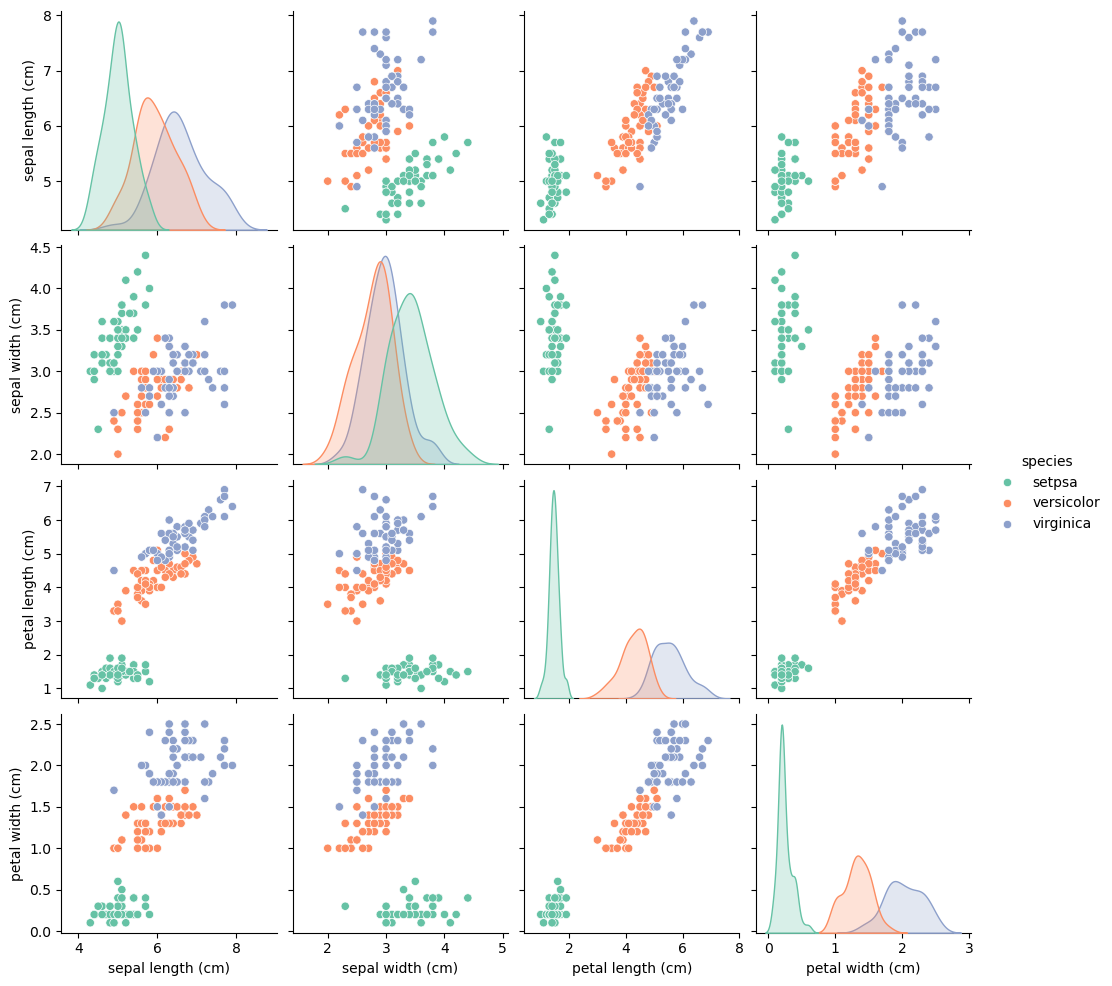

In [10]:
sns.pairplot(data=df,hue="species",palette="Set2")

## Train Test Split

In [11]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=1)

In [12]:
x_train.shape
y_train.shape

(120,)

## Feature scaling

In [15]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [16]:
from sklearn.svm import SVC
svm=SVC(kernel="linear",random_state=0)
svm.fit(x_train,y_train)

SVC(kernel='linear', random_state=0)

In [17]:
y_pred=svm.predict(x_test)
y_pred

array([0, 1, 1, 0, 2, 1, 2, 0, 0, 2, 1, 0, 2, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       2, 0, 2, 1, 0, 0, 1, 2])

In [18]:
y_test

array([0, 1, 1, 0, 2, 1, 2, 0, 0, 2, 1, 0, 2, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       1, 0, 2, 1, 0, 0, 1, 2])

In [19]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
AS=accuracy_score(y_test,y_pred)
AS

0.9666666666666667

In [20]:
CM=confusion_matrix(y_test,y_pred)
CM

array([[11,  0,  0],
       [ 0, 12,  1],
       [ 0,  0,  6]])

In [21]:
CR=classification_report(y_test,y_pred)
print(CR)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      0.92      0.96        13
           2       0.86      1.00      0.92         6

    accuracy                           0.97        30
   macro avg       0.95      0.97      0.96        30
weighted avg       0.97      0.97      0.97        30



In [22]:
rbf_svm=SVC(kernel="rbf",random_state=0)
rbf_svm.fit(x_train,y_train)
rbf_pred=rbf_svm.predict(x_test)
rbf_pred


array([0, 1, 1, 0, 2, 1, 2, 0, 0, 2, 1, 0, 2, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       2, 0, 2, 1, 0, 0, 1, 2])

In [23]:
AS=accuracy_score(y_test,rbf_pred)
AS

0.9666666666666667

In [24]:
CM=confusion_matrix(y_test,rbf_pred)
CM

array([[11,  0,  0],
       [ 0, 12,  1],
       [ 0,  0,  6]])

In [ ]:
CR=classification_report(y_test,rbf_pred)
print(CR)